# Bank Marketing — Dự đoán đăng ký tiền gửi có kỳ hạn 


## 1. Thư viện và cấu hình

In [1]:
import importlib.util, subprocess, sys
for pkg in ['optuna', 'xgboost']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42
N_TRIALS     = 50
DATA_PATH    = 'bank_data_cleaned.csv'
CV           = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Đọc dữ liệu


In [3]:
df = pd.read_csv(DATA_PATH)
y = df['y']
print('Shape:', df.shape, '| ô thiếu:', int(df.isna().sum().sum()))
print('Tỷ lệ y=1:', round(y.mean(), 4))
df.head()

Shape: (45208, 17) | ô thiếu: 0
Tỷ lệ y=1: 0.117


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143.0,yes,no,unknown,5,may,261.0,1.0,-1.0,0.0,nonexistent,0
1,44,technician,single,secondary,no,29.0,yes,no,unknown,5,may,151.0,1.0,-1.0,0.0,nonexistent,0
2,33,entrepreneur,married,secondary,no,2.0,yes,yes,unknown,5,may,76.0,1.0,-1.0,0.0,nonexistent,0
3,47,blue-collar,married,secondary,no,1506.0,yes,no,unknown,5,may,92.0,1.0,-1.0,0.0,nonexistent,0
4,33,blue-collar,single,secondary,no,1.0,no,no,unknown,5,may,198.0,1.0,-1.0,0.0,nonexistent,0


## 3. Feature engineering
- Bỏ `day` (ít ý nghĩa kinh doanh) và bỏ `duration` (chỉ biết sau cuộc gọi, gây target leakage).
- `pdays = -1` nghĩa là chưa từng liên hệ: tách thành `was_contacted_before`, rồi thay -1 bằng 0.
- Mã hóa `default`, `housing`, `loan` thành 1/0 (phép ánh xạ cố định, không phụ thuộc dữ liệu).

In [4]:
CAT_COLS = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
NUM_ALL  = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']

def build_features(df, use_duration=False):
    X = df.drop(columns=['y', 'day'])
    if not use_duration:
        X = X.drop(columns=['duration'])
    X['was_contacted_before'] = (X['pdays'] != -1).astype(int)
    X['pdays'] = X['pdays'].replace(-1, 0)
    for c in ['default', 'housing', 'loan']:
        X[c] = X[c].map({'yes': 1, 'no': 0})
    return X

X = build_features(df)
print('Số features thô:', X.shape[1])
print(X.columns.tolist())

Số features thô: 15
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'was_contacted_before']


In [6]:
print("Số giá trị mỗi cột:")
print(X[CAT_COLS].nunique())

Số giá trị mỗi cột:
job          11
marital       3
education     3
contact       3
month        12
poutcome      5
dtype: int64


## 4. Chia train / test
Chia 80/20 có `stratify=y`. Dùng chỉ số dòng để các phần sau (kể cả phụ lục `duration`) dùng đúng cùng một cách chia.

In [5]:
idx = np.arange(len(df))
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
import numpy as np
np.save('idx_train.npy', idx_train)
np.save('idx_test.npy', idx_test)

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
print(f'Train: {len(X_train)} | Test: {len(X_test)}')
print('Tỷ lệ y=1 — train:', round(y_train.mean(), 4), '| test:', round(y_test.mean(), 4))
X_test.head ()

Train: 36166 | Test: 9042
Tỷ lệ y=1 — train: 0.117 | test: 0.117


,age,job,marital,education,default,balance,housing,loan,contact,month,campaign,pdays,previous,poutcome,was_contacted_before
11785,43,entrepreneur,married,secondary,0,0.0,1,0,unknown,jun,1.0,0.0,0.0,nonexistent,0
14769,44,services,married,secondary,0,850.0,0,1,cellular,jul,5.0,0.0,0.0,nonexistent,0
1026,40,technician,married,primary,0,164.0,1,0,unknown,may,1.0,0.0,0.0,nonexistent,0
22441,35,technician,single,tertiary,0,296.0,0,0,cellular,aug,2.0,0.0,0.0,nonexistent,0
40761,40,blue-collar,married,secondary,0,1508.0,0,0,cellular,aug,2.0,383.0,1.0,failure,1


In [6]:
print(df.shape)
print(X_test.index[:10].tolist())
print(len(X_train), len(X_test))

(45208, 17)
[11785, 14769, 1026, 22441, 40761, 27521, 43835, 36140, 38013, 35360]
36166 9042


## 5. Pipeline và mô hình
Mỗi mô hình là một `Pipeline` gồm bước tiền xử lý (one-hot cho biến phân loại, `StandardScaler` cho biến số chỉ với Logistic Regression) và bước mô hình. Khi cross-validation, scaler và encoder được fit lại trong từng fold nên không rò rỉ thông tin từ fold validation.

In [6]:
def make_pipe(X, model, scale):
    num = [c for c in NUM_ALL if c in X.columns]
    pre = ColumnTransformer(
        [('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), CAT_COLS),
         ('num', StandardScaler() if scale else 'passthrough', num)],
        remainder='passthrough', verbose_feature_names_out=False)
    return Pipeline([('pre', pre), ('model', model)])

## 6. Tối ưu tham số bằng Optuna
| Cài đặt | Giá trị |
|---|---|
| Sampler | TPE |
| Metric tối ưu | PR-AUC (`average_precision`) |
| Cross-validation | StratifiedKFold 5-fold trên tập train |
| Số trial | `N_TRIALS` mỗi mô hình |


In [7]:
def cv_pr_auc(pipe):
    return cross_val_score(pipe, X_train, y_train, cv=CV,
                           scoring='average_precision', n_jobs=-1).mean()

def run_study(objective, label):
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    print(f'{label}: best CV PR-AUC = {study.best_value:.4f}')
    print('  params:', study.best_params)
    return study

### 6.1 Logistic Regression

In [8]:
def lr_params_from(params):
    p = dict(params)
    for alias in ['penalty_ll', 'penalty_saga']:
        if alias in p:
            p['penalty'] = p.pop(alias)
    p.setdefault('penalty', 'l2')
    return p

def objective_lr(trial):
    solver = trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga'])
    params = {
        'C'           : trial.suggest_float('C', 1e-3, 100, log=True),
        'solver'      : solver,
        'max_iter'    : trial.suggest_int('max_iter', 200, 2000),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
    }
    if solver == 'liblinear':
        params['penalty'] = trial.suggest_categorical('penalty_ll', ['l1', 'l2'])
    elif solver == 'saga':
        params['penalty'] = trial.suggest_categorical('penalty_saga', ['l1', 'l2', 'elasticnet'])
        if params['penalty'] == 'elasticnet':
            params['l1_ratio'] = trial.suggest_float('l1_ratio', 0.0, 1.0)
    else:
        params['penalty'] = 'l2'
    pipe = make_pipe(X_train, LogisticRegression(**params, random_state=RANDOM_STATE), scale=True)
    return cv_pr_auc(pipe)

study_lr = run_study(objective_lr, 'Logistic Regression')

  0%|          | 0/50 [00:00<?, ?it/s]

Logistic Regression: best CV PR-AUC = 0.4051
  params: {'solver': 'saga', 'C': 0.2878553747252366, 'max_iter': 1439, 'class_weight': None, 'penalty_saga': 'l1'}


### 6.2 Random Forest

In [9]:
def objective_rf(trial):
    params = {
        'n_estimators'     : trial.suggest_int('n_estimators', 100, 500),
        'max_depth'        : trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'class_weight'     : trial.suggest_categorical('class_weight', [None, 'balanced']),
    }
    pipe = make_pipe(X_train, RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=1), scale=False)
    return cv_pr_auc(pipe)

study_rf = run_study(objective_rf, 'Random Forest')

  0%|          | 0/50 [00:00<?, ?it/s]

Random Forest: best CV PR-AUC = 0.4286
  params: {'n_estimators': 145, 'max_depth': 20, 'min_samples_split': 20, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'class_weight': None}


### 6.3 XGBoost

In [10]:
def objective_xgb(trial):
    params = {
        'n_estimators'    : trial.suggest_int('n_estimators', 100, 500),
        'max_depth'       : trial.suggest_int('max_depth', 3, 10),
        'learning_rate'   : trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
        'subsample'       : trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma'           : trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
    }
    pipe = make_pipe(X_train, XGBClassifier(**params, eval_metric='logloss',
                                            random_state=RANDOM_STATE, n_jobs=1, verbosity=0), scale=False)
    return cv_pr_auc(pipe)

study_xgb = run_study(objective_xgb, 'XGBoost')

  0%|          | 0/50 [00:00<?, ?it/s]

XGBoost: best CV PR-AUC = 0.4366
  params: {'n_estimators': 439, 'max_depth': 10, 'learning_rate': 0.007818028084691061, 'subsample': 0.7876529545790868, 'colsample_bytree': 0.6709847661398739, 'min_child_weight': 1, 'gamma': 3.6567016904431044, 'reg_alpha': 0.2276310268388166, 'reg_lambda': 0.19949581148396933}


## 7. CV, chọn ngưỡng và huấn luyện
Gồm 4 mô hình: Logistic Regression baseline (tham số mặc định, `class_weight='balanced'`) và 3 mô hình đã tối ưu.

Với mỗi mô hình:
- **CV PR-AUC** trên tập train, dùng để chọn mô hình.
- **Ngưỡng tối ưu F1** chọn trên xác suất out-of-fold của tập train.
- Huấn luyện lại trên toàn bộ train, rồi dự đoán test.

In [11]:
def make_models(X):
    lr_best = lr_params_from(study_lr.best_params)
    return {
        'LR Baseline': make_pipe(X, LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                                       solver='lbfgs', class_weight='balanced'), True),
        'LR (Tuned)' : make_pipe(X, LogisticRegression(**lr_best, random_state=RANDOM_STATE), True),
        'RF (Tuned)' : make_pipe(X, RandomForestClassifier(**study_rf.best_params,
                                    random_state=RANDOM_STATE, n_jobs=-1), False),
        'XGB (Tuned)': make_pipe(X, XGBClassifier(**study_xgb.best_params, eval_metric='logloss',
                                    random_state=RANDOM_STATE, n_jobs=-1, verbosity=0), False),
    }

def best_f1_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])

models = make_models(X_train)
cv_pr, thresholds, proba_train, proba_test = {}, {}, {}, {}

for name, pipe in models.items():
    cv_pr[name] = cv_pr_auc(pipe)
    oof = cross_val_predict(pipe, X_train, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]
    thresholds[name] = best_f1_threshold(y_train, oof)
    pipe.fit(X_train, y_train)
    proba_train[name] = pipe.predict_proba(X_train)[:, 1]
    proba_test[name]  = pipe.predict_proba(X_test)[:, 1]

cv_pr = pd.Series(cv_pr, name='CV PR-AUC (train)')
selected = cv_pr.idxmax()
print(cv_pr.round(4).to_string())
print('\nNgưỡng tối ưu F1 (chọn trên out-of-fold):')
print(pd.Series(thresholds).round(3).to_string())
print(f'\nMô hình được chọn theo CV PR-AUC: {selected}')

LR Baseline    0.4018
LR (Tuned)     0.4051
RF (Tuned)     0.4286
XGB (Tuned)    0.4366

Ngưỡng tối ưu F1 (chọn trên out-of-fold):
LR Baseline    0.641
LR (Tuned)     0.199
RF (Tuned)     0.214
XGB (Tuned)    0.189

Mô hình được chọn theo CV PR-AUC: XGB (Tuned)


## 8. Kết quả trên test set
Test set chỉ dùng để báo cáo, không dùng để chọn mô hình hay ngưỡng.
- **Bảng 1:** ngưỡng 0,5 (mặc định).
- **Bảng 2:** ngưỡng tối ưu F1 đã chọn ở phần 7. ROC-AUC và PR-AUC không phụ thuộc ngưỡng nên giống nhau ở hai bảng.

Accuracy, Precision, Recall, F1 phụ thuộc ngưỡng và `class_weight`, nên so sánh giữa các mô hình nên dựa chủ yếu vào ROC-AUC và PR-AUC.

In [12]:
def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {
        'Accuracy' : accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall'   : recall_score(y_true, pred),
        'F1-Score' : f1_score(y_true, pred),
        'ROC-AUC'  : roc_auc_score(y_true, proba),
        'PR-AUC'   : average_precision_score(y_true, proba),
    }

tbl_05  = pd.DataFrame({n: metrics_at(y_test, p, 0.5) for n, p in proba_test.items()}).T
tbl_thr = pd.DataFrame({n: metrics_at(y_test, p, thresholds[n]) for n, p in proba_test.items()}).T
tbl_thr.insert(0, 'Ngưỡng', pd.Series(thresholds))

print('BẢNG 1 — Test set, ngưỡng 0.5')
display(tbl_05.round(4))
print('BẢNG 2 — Test set, ngưỡng tối ưu F1 (chọn trên OOF của train)')
display(tbl_thr.round(4))

BẢNG 1 — Test set, ngưỡng 0.5


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
LR Baseline,0.7702,0.2864,0.6465,0.3970,0.7790,0.4188
LR (Tuned),0.8945,0.6970,0.1739,0.2784,0.7797,0.4208
RF (Tuned),0.8964,0.7266,0.1834,0.2928,0.7943,0.4411
XGB (Tuned),0.8968,0.7224,0.1919,0.3032,0.7974,0.4548


BẢNG 2 — Test set, ngưỡng tối ưu F1 (chọn trên OOF của train)


,Ngưỡng,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
LR Baseline,0.6414,0.8728,0.4551,0.4405,0.4476,0.7790,0.4188
LR (Tuned),0.1989,0.8751,0.4647,0.4423,0.4533,0.7797,0.4208
RF (Tuned),0.2140,0.8694,0.4490,0.5113,0.4781,0.7943,0.4411
XGB (Tuned),0.1894,0.8699,0.4514,0.5180,0.4824,0.7974,0.4548


1. Ở ngưỡng 0.5, các mô hình Tuned (LR, RF, XGB) bị rơi vào trạng thái cực kỳ "nhút nhát":


* Precision rất cao (~72%): Đội telesales gọi cuộc nào là chắc cuộc đó (10 cuộc thì hơn 7 cuộc chốt được deposit).
* Recall quá thấp (~18% - 19%): Mô hình bỏ sót tới hơn 80% lượng khách hàng thực sự có nhu cầu gửi tiền.
* Kết luận: Ngưỡng 0.5 không hiệu quả vì nó làm chiến dịch bị bó hẹp, bỏ lỡ quá nhiều doanh thu.

2. Cấu hình lại ngưỡng cắt (hạ ngưỡng xuống quanh mức 0.18 - 0.21 cho các mô hình Tuned), cục diện thay đổi hoàn toàn theo hướng có lợi cho Telesales:
* Recall tăng vọt lên ~52%: Bạn đã "vớt" được hơn một nửa tổng số khách hàng thực sự muốn deposit ngoài thực tế (gấp gần 3 lần so với bảng 1).
* Precision giữ ở mức ~45%: Tuy giảm so với bảng 1, nhưng mức 45% này vẫn cao gấp 4 lần tỷ lệ tự nhiên (11%). Cứ gọi khoảng 2 cuộc thì bạn có 1 cuộc thành công. Đây là hiệu suất cực kỳ cao đối với đội ngũ Telesales.
* F1-Score đạt đỉnh: XGBoost (Tuned) dẫn đầu với F1 = 0.4824 tại ngưỡng 0.1894.

Khuyến nghị hành động triển khai (Actionable Insight): chọn mô hình XGBoost (Tuned) và xuất xác suất dự đoán của tập khách hàng mới ra.
1. Lọc danh sách gọi: Chỉ giao cho Telesales những khách hàng có xác suất dự đoán \(\ge \) 0.1894(đây chính là ngưỡng tối ưu ở Bảng 2).
2. Kỳ vọng đạt được: Đội Telesales của bạn sẽ đạt tỷ lệ chốt đơn (Hit-rate) khoảng 45%, và chiến dịch sẽ mang về được 51.8% tổng số lượng tiền gửi tiềm năng hiện có trên thị trường.


## 9. Kiểm tra overfitting
So sánh PR-AUC trên train, CV (train) và test. Gap lớn giữa train và CV/test cho thấy overfitting. Pipeline được dùng nguyên vẹn nên dữ liệu đưa vào luôn đúng dạng đã huấn luyện.

In [13]:
overfit = pd.DataFrame({
    'Train PR-AUC': {n: average_precision_score(y_train, p) for n, p in proba_train.items()},
    'CV PR-AUC'   : cv_pr,
    'Test PR-AUC' : {n: average_precision_score(y_test, p) for n, p in proba_test.items()},
})
overfit['Gap (Train - Test)'] = overfit['Train PR-AUC'] - overfit['Test PR-AUC']
overfit.round(4)

,Train PR-AUC,CV PR-AUC,Test PR-AUC,Gap (Train - Test)
LR Baseline,0.4035,0.4018,0.4188,-0.0153
LR (Tuned),0.4071,0.4051,0.4208,-0.0137
RF (Tuned),0.6055,0.4286,0.4411,0.1644
XGB (Tuned),0.5153,0.4366,0.4548,0.0605


## 10. Biểu đồ
ROC-AUC và PR-AUC của các mô hình, đường Precision-Recall, và confusion matrix tại ngưỡng tối ưu F1.

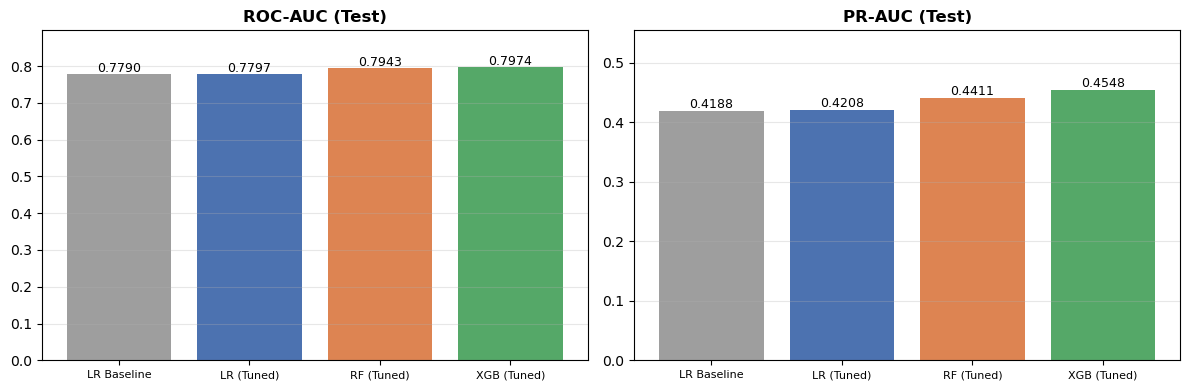

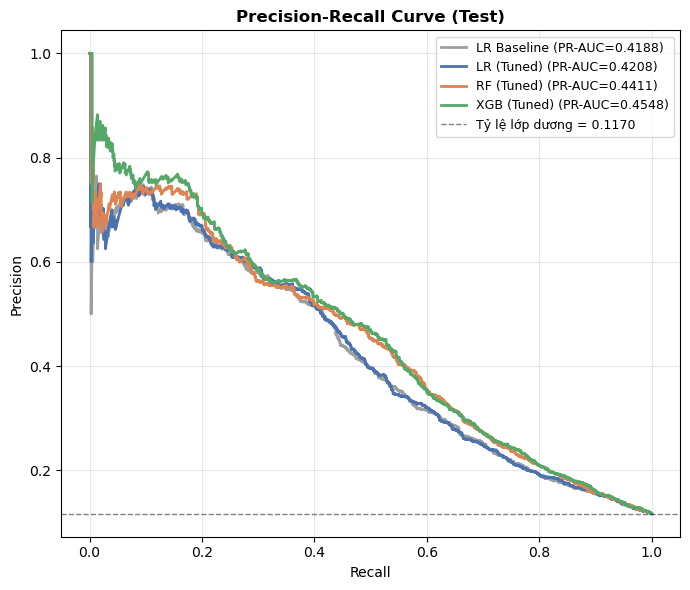

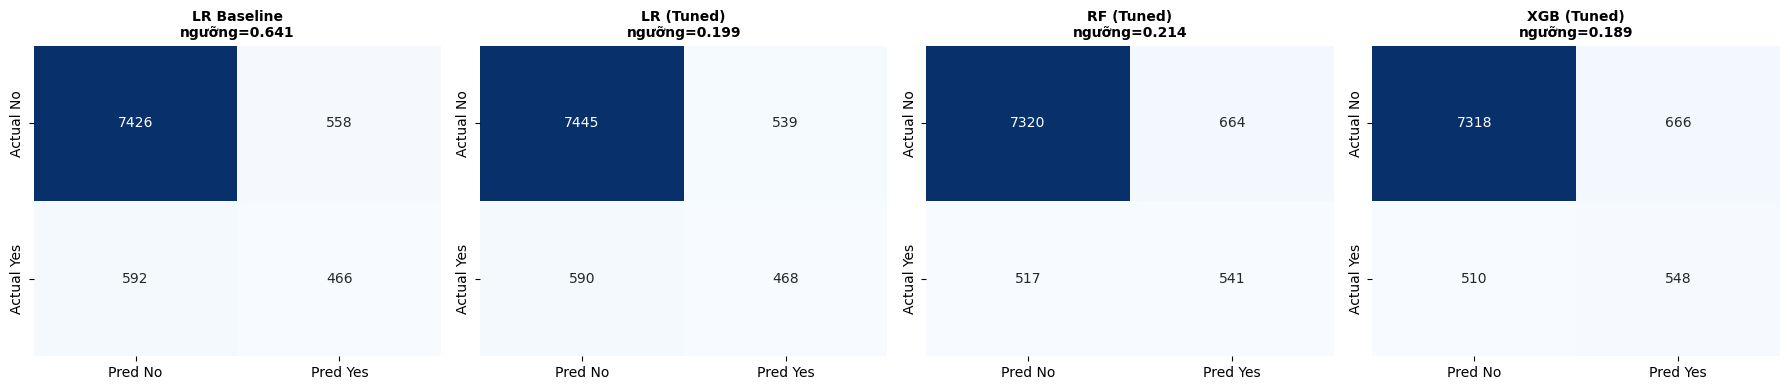

In [14]:
colors = {'LR Baseline': '#9E9E9E', 'LR (Tuned)': '#4C72B0', 'RF (Tuned)': '#DD8452', 'XGB (Tuned)': '#55A868'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['ROC-AUC', 'PR-AUC']):
    vals = tbl_05[metric]
    bars = ax.bar(vals.index, vals.values, color=[colors[n] for n in vals.index])
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f'{v:.4f}', ha='center', fontsize=9)
    ax.set_title(f'{metric} (Test)', fontweight='bold')
    ax.set_ylim(0, min(1.05, vals.max() + 0.1))
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for n, p in proba_test.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, color=colors[n], lw=2, label=f'{n} (PR-AUC={average_precision_score(y_test, p):.4f})')
ax.axhline(y_test.mean(), color='k', ls='--', lw=1, alpha=0.5,
           label=f'Tỷ lệ lớp dương = {y_test.mean():.4f}')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve (Test)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (n, p) in zip(axes, proba_test.items()):
    cm = confusion_matrix(y_test, (p >= thresholds[n]).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred No', 'Pred Yes'], yticklabels=['Actual No', 'Actual Yes'])
    ax.set_title(f'{n}\nngưỡng={thresholds[n]:.3f}', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

XGB:
Phát hiện đúng 548 khách hàng Yes.

Bỏ sót 510 khách hàng Yes.

Có 666 khách hàng No bị dự đoán nhầm thành Yes.

Mô hình phát hiện được khoảng 51.8% khách hàng thực sự thuộc nhóm Yes, nhưng vẫn có nhiều false positive. Đây là đánh đổi cần cân nhắc dựa trên chi phí liên hệ khách hàng và lợi ích khi tìm được khách hàng tiềm năng.

## 11. Feature importance
Hệ số cho Logistic Regression (biến số đã chuẩn hóa), Gini importance cho Random Forest, importance mặc định của XGBoost. Hiển thị top 15 của mô hình đã tối ưu.

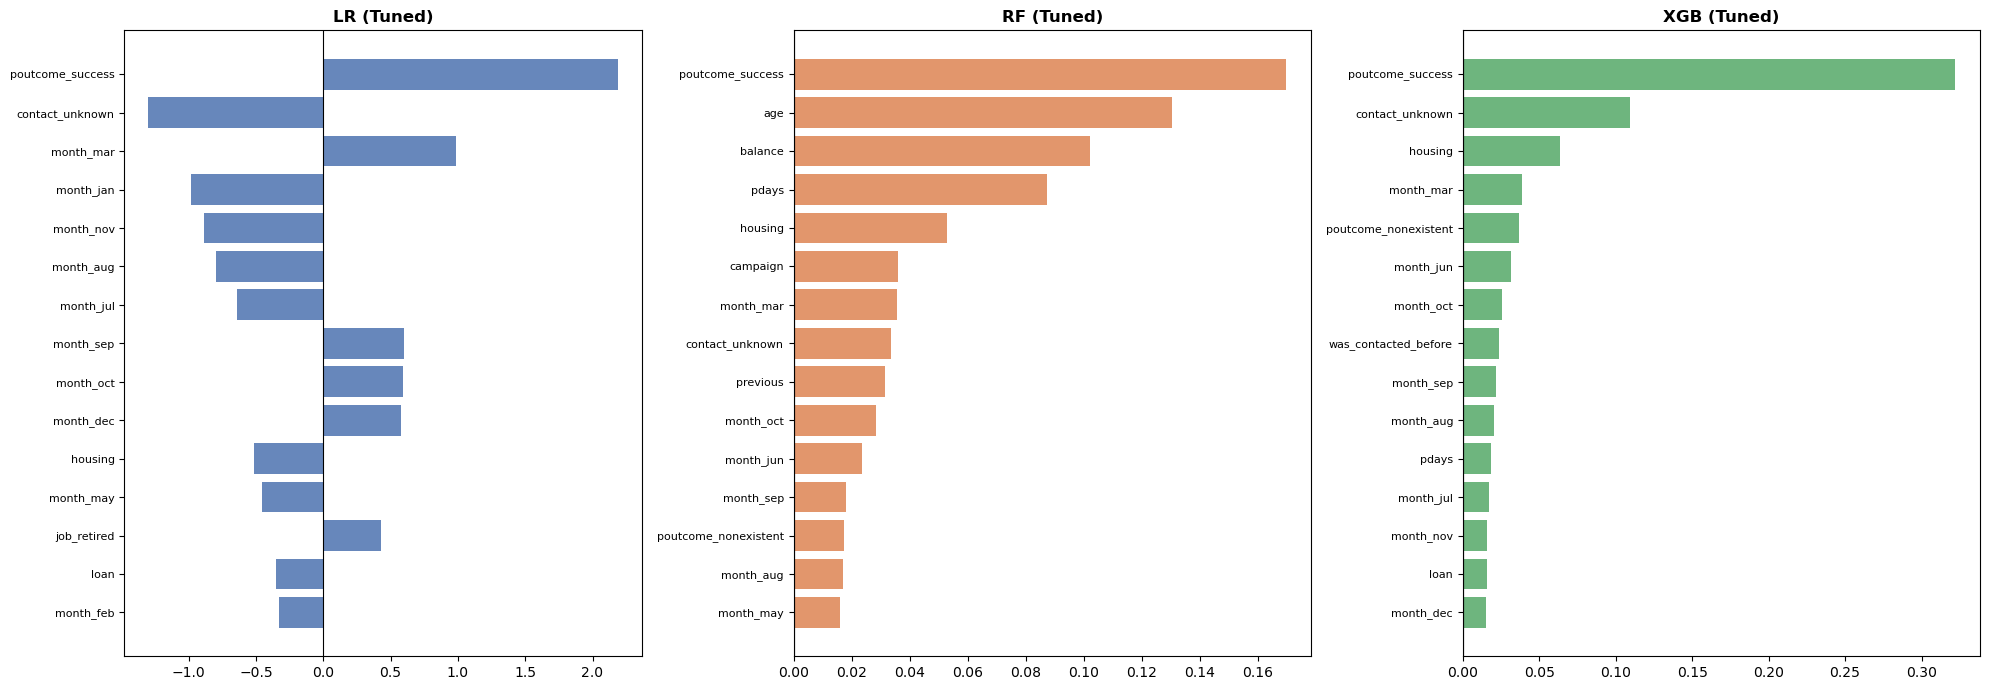

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, name in zip(axes, ['LR (Tuned)', 'RF (Tuned)', 'XGB (Tuned)']):
    pipe = models[name]
    names = pipe.named_steps['pre'].get_feature_names_out()
    est = pipe.named_steps['model']
    vals = est.coef_[0] if name.startswith('LR') else est.feature_importances_
    imp = pd.Series(vals, index=names).sort_values(key=abs, ascending=False).head(15)
    ax.barh(imp.index, imp.values, color=colors[name], alpha=0.85)
    ax.invert_yaxis(); ax.axvline(0, color='k', lw=0.8)
    ax.set_title(name, fontweight='bold'); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

## 12. Kiểm tra theo thời gian
Dữ liệu gốc được sắp xếp theo thời gian và file cleaned giữ nguyên thứ tự dòng. Ở đây huấn luyện trên 80% dòng đầu và kiểm tra trên 20% dòng cuối, với cùng tham số đã tối ưu. Đây là cách đánh giá gần với triển khai thực tế hơn chia ngẫu nhiên; nếu tỷ lệ `y=1` hoặc điểm số khác nhiều, mô hình nhạy với thay đổi theo thời gian. Lưu ý PR-AUC phụ thuộc tỷ lệ lớp dương nên không so sánh trực tiếp giữa hai cách chia; so sánh bằng ROC-AUC.

In [16]:
n_tr = int(len(df) * 0.8)
t_tr, t_te = idx[:n_tr], idx[n_tr:]
print('Tỷ lệ y=1 — giai đoạn đầu (train):', round(y.iloc[t_tr].mean(), 4),
      '| giai đoạn cuối (test):', round(y.iloc[t_te].mean(), 4))

rows = {}
for name, pipe in make_models(X).items():
    pipe.fit(X.iloc[t_tr], y.iloc[t_tr])
    pr = pipe.predict_proba(X.iloc[t_te])[:, 1]
    rows[name] = {'ROC-AUC (thời gian)': roc_auc_score(y.iloc[t_te], pr),
                  'PR-AUC (thời gian)' : average_precision_score(y.iloc[t_te], pr)}
temporal = pd.DataFrame(rows).T
temporal['ROC-AUC (chia ngẫu nhiên)'] = tbl_05['ROC-AUC']
temporal['PR-AUC (chia ngẫu nhiên)']  = tbl_05['PR-AUC']
temporal.round(4)

Tỷ lệ y=1 — giai đoạn đầu (train): 0.0673 | giai đoạn cuối (test): 0.3159


,ROC-AUC (thời gian),PR-AUC (thời gian),ROC-AUC (chia ngẫu nhiên),PR-AUC (chia ngẫu nhiên)
LR Baseline,0.6909,0.4917,0.7790,0.4188
LR (Tuned),0.6922,0.4909,0.7797,0.4208
RF (Tuned),0.6936,0.4592,0.7943,0.4411
XGB (Tuned),0.7027,0.4817,0.7974,0.4548


Tỷ lệ "yes" nhảy từ 6,7% (giai đoạn đầu) lên 31,6% (giai đoạn cuối), tức phân phối khách hàng thay đổi rất nhiều theo thời gian.

ROC-AUC của cả 4 mô hình giảm từ khoảng 0,78–0,80 xuống 0,69–0,70. Khi đó XGB vẫn cao nhất (0,7027) nhưng LR (0,6922) gần như ngang, nên lợi thế của mô hình phức tạp không còn rõ.

kết quả chia ngẫu nhiên lạc quan hơn thực tế triển khai theo thời gian. Ngưỡng chọn trên giai đoạn cũ cũng sẽ lệch khi tỷ lệ "yes" thay đổi, nên cần cập nhật ngưỡng định kỳ.

## 13. Phụ lục: ảnh hưởng của `duration`
`duration` chỉ biết sau khi cuộc gọi kết thúc nên không dùng được khi dự đoán trước cuộc gọi. Phần này huấn luyện lại cùng mô hình (cùng tham số, cùng cách chia train/test) **có thêm `duration`** để đo mức chênh lệch so với mô hình chính. Kết quả có `duration` chỉ là cận trên mang tính tham khảo.

In [17]:
X_dur = build_features(df, use_duration=True)
rows = {}
for name, pipe in make_models(X_dur).items():
    pipe.fit(X_dur.iloc[idx_train], y_train)
    pr = pipe.predict_proba(X_dur.iloc[idx_test])[:, 1]
    rows[name] = {'ROC-AUC (có duration)': roc_auc_score(y_test, pr),
                  'PR-AUC (có duration)' : average_precision_score(y_test, pr)}
dur_tbl = pd.DataFrame(rows).T
dur_tbl['ROC-AUC (không duration)'] = tbl_05['ROC-AUC']
dur_tbl['PR-AUC (không duration)']  = tbl_05['PR-AUC']
dur_tbl['Δ PR-AUC'] = dur_tbl['PR-AUC (có duration)'] - dur_tbl['PR-AUC (không duration)']
dur_tbl.round(4)

,ROC-AUC (có duration),PR-AUC (có duration),ROC-AUC (không duration),PR-AUC (không duration),Δ PR-AUC
LR Baseline,0.9076,0.5628,0.7790,0.4188,0.1440
LR (Tuned),0.9075,0.5684,0.7797,0.4208,0.1475
RF (Tuned),0.9259,0.6123,0.7943,0.4411,0.1712
XGB (Tuned),0.9275,0.6203,0.7974,0.4548,0.1655


Thêm duration làm PR-AUC tăng 0,14–0,17 (XGB: 0,4548 lên 0,6203) và ROC-AUC lên 0,91–0,93.

## 14. Kết luận
Tóm tắt sinh tự động từ các kết quả ở trên.

In [18]:
best = selected
print('=' * 70)
print('KẾT LUẬN')
print('=' * 70)
print(f'Mô hình được chọn theo CV PR-AUC (không dùng test): {best}')
print(f'  CV PR-AUC   : {cv_pr[best]:.4f}')
print(f'  Test PR-AUC : {tbl_05.loc[best, "PR-AUC"]:.4f} | Test ROC-AUC: {tbl_05.loc[best, "ROC-AUC"]:.4f}')
print(f'  Tại ngưỡng {thresholds[best]:.3f}: Precision={tbl_thr.loc[best, "Precision"]:.4f}, '
      f'Recall={tbl_thr.loc[best, "Recall"]:.4f}, F1={tbl_thr.loc[best, "F1-Score"]:.4f}')
print(f'  Gap PR-AUC (train - test): {overfit.loc[best, "Gap (Train - Test)"]:.4f}')
print(f'  ROC-AUC khi chia theo thời gian: {temporal.loc[best, "ROC-AUC (thời gian)"]:.4f} '
      f'(chia ngẫu nhiên: {temporal.loc[best, "ROC-AUC (chia ngẫu nhiên)"]:.4f})')
print(f'  PR-AUC khi thêm duration: {dur_tbl.loc[best, "PR-AUC (có duration)"]:.4f} '
      f'(Δ = {dur_tbl.loc[best, "Δ PR-AUC"]:+.4f})')
print('=' * 70)

KẾT LUẬN
Mô hình được chọn theo CV PR-AUC (không dùng test): XGB (Tuned)
  CV PR-AUC   : 0.4366
  Test PR-AUC : 0.4548 | Test ROC-AUC: 0.7974
  Tại ngưỡng 0.189: Precision=0.4514, Recall=0.5180, F1=0.4824
  Gap PR-AUC (train - test): 0.0605
  ROC-AUC khi chia theo thời gian: 0.7027 (chia ngẫu nhiên: 0.7974)
  PR-AUC khi thêm duration: 0.6203 (Δ = +0.1655)
